In [ ]:
!pip install kaggle

In [ ]:
import os

!mkdir -p ~/.kaggle

!chmod 600 ~/.kaggle/kaggle.json

chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory


In [ ]:
# Download the dataset
# The dataset is 'grassknoted/asl-alphabet'
# It will be downloaded to the current working directory

DATASET_NAME = 'grassknoted/asl-alphabet'

# Make sure the 'data' directory exists for extraction
!mkdir -p data

# Download the dataset. The -p flag preserves the file hierarchy in the archive.
!kaggle datasets download -d {DATASET_NAME} -p data

# Unzip the downloaded file
# The dataset name might be part of the zip file, or it could be 'asl-alphabet.zip'
# Check the contents of the downloaded 'data' folder to confirm the zip file name
# For this dataset, it typically downloads as asl-alphabet.zip

# Assuming the zip file is named 'asl-alphabet.zip' inside the 'data' directory
import zipfile
import os

zip_file_path = 'data/asl-alphabet.zip'
extract_path = 'data/' # Extract directly into the data folder

if os.path.exists(zip_file_path):
    with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print(f"Successfully extracted {zip_file_path} to {extract_path}")
    # Optionally remove the zip file after extraction
    !rm {zip_file_path}
else:
    print(f"Error: Zip file not found at {zip_file_path}")

# Verify the extracted content
!ls data/asl_alphabet_train

Dataset URL: https://www.kaggle.com/datasets/grassknoted/asl-alphabet
License(s): GPL-2.0
100% 1.03G/1.03G [00:10<00:00, 101MB/s] 

Successfully extracted data/asl-alphabet.zip to data/
asl_alphabet_train


In [ ]:
from pathlib import Path
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from tensorflow.keras.optimizers import Adam, SGD

SEED = 42
IMG_SIZE = (64, 64)
BATCH_SIZE = 32
DATA_DIR = Path("data/asl_alphabet_train")

tf.keras.utils.set_random_seed(SEED)
assert DATA_DIR.is_dir(), f"Dataset folder not found: {DATA_DIR.resolve()}"

In [ ]:
# Automatically resolve nested directory structure if present
if (DATA_DIR / "asl_alphabet_train").is_dir():
    DATA_DIR = DATA_DIR / "asl_alphabet_train"

class_names = sorted(p.name for p in DATA_DIR.iterdir() if p.is_dir())
NUM_CLASSES = len(class_names)
assert NUM_CLASSES == 29, f"Expected 29 classes, found {NUM_CLASSES}"

records = [
    (str(path), label, name)
    for label, name in enumerate(class_names)
    for path in sorted((DATA_DIR / name).iterdir())
    if path.suffix.lower() in {".jpg", ".jpeg", ".png"}
]

df = pd.DataFrame(records, columns=["path", "label", "class_name"])

print(f"Images: {len(df):,} | Classes: {NUM_CLASSES}")
display(df.groupby("class_name").size().rename("images").to_frame())

Images: 87,000 | Classes: 29


,images
class_name,
A,3000
B,3000
C,3000
D,3000
E,3000
F,3000
G,3000
H,3000
I,3000


In [ ]:
train_df, remaining_df = train_test_split(
    df, test_size=0.30, stratify=df["label"], random_state=SEED
)

val_df, test_df = train_test_split(
    remaining_df,
    test_size=0.50,
    stratify=remaining_df["label"],
    random_state=SEED
)

Path("splits").mkdir(exist_ok=True)

for name, part in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df)
]:
    part.to_csv(f"splits/{name}.csv", index=False)
    print(f"{name:10s}: {len(part):,} images ({len(part)/len(df):.0%})")

train     : 60,900 images (70%)
validation: 13,050 images (15%)
test      : 13,050 images (15%)


In [ ]:
def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE, antialias=True)
    return image, label

def make_dataset(frame, training=False):
    ds = tf.data.Dataset.from_tensor_slices((
        frame["path"].to_numpy(),
        frame["label"].to_numpy(dtype="int32")
    ))

    if training:
        ds = ds.shuffle(len(frame), seed=SEED)

    return (
        ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
          .batch(BATCH_SIZE)
          .prefetch(tf.data.AUTOTUNE)
    )

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

images, labels = next(iter(train_ds))
print("Image batch:", images.shape)   # (32, 64, 64, 3)
print("Label batch:", labels.shape)   # (32,)

Image batch: (32, 64, 64, 3)
Label batch: (32,)


## Model A

In [ ]:
from tensorflow.keras import layers, models

def build_model_A():
    return models.Sequential([
        layers.Input(shape=(64, 64, 3)),
        layers.Rescaling(1./255),

        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(2),

        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(2),

        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(2),

        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(2),

        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.25),
        layers.Dense(NUM_CLASSES, activation="softmax")
    ], name="Model_A")

model_A = build_model_A()
model_A.summary()

Model: "Model_A"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 29)             │         3,741 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 244,573 (955.36 KB)

 Trainable params: 244,573 (955.36 KB)

 Non-trainable params: 0 (0.00 B)

## Model B

In [ ]:
def build_model_B():
    return models.Sequential([
        layers.Input(shape=(64, 64, 3)),
        layers.Rescaling(1./255),

        layers.SeparableConv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(2),

        layers.SeparableConv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(2),

        layers.SeparableConv2D(128, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(2),

        layers.SeparableConv2D(128, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(2),

        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.25),
        layers.Dense(NUM_CLASSES, activation="softmax")
    ], name="Model_B")

model_B = build_model_B()
model_B.summary()

trainable_B = sum(
    int(tf.size(weight).numpy()) for weight in model_B.trainable_weights
)
assert trainable_B <= 100_000
print("Model B trainable parameters:", trainable_B)

Model: "Model_B"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d                │ (None, 64, 64, 32)     │           155 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_1              │ (None, 32, 32, 64)     │         2,400 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_2              │ (None, 16, 16, 128)    │         8,896 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_3              │ (None, 8, 8, 128)      │        17,664 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 29)             │         3,741 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,856 (128.34 KB)

 Trainable params: 32,856 (128.34 KB)

 Non-trainable params: 0 (0.00 B)

Model B trainable parameters: 32856


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.optimizers import Adam, SGD

tf.keras.utils.set_random_seed(SEED)

initial_model = tf.keras.models.clone_model(model_A)
initial_weights = initial_model.get_weights()

In [ ]:
tf.keras.utils.set_random_seed(SEED)

model_adam = tf.keras.models.clone_model(initial_model)
model_adam.set_weights(initial_weights)

model_adam.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_adam = model_adam.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    verbose=2
)

Epoch 1/20
1904/1904 - 74s - 39ms/step - accuracy: 0.6073 - loss: 1.2814 - val_accuracy: 0.9311 - val_loss: 0.2339
Epoch 2/20
1904/1904 - 56s - 29ms/step - accuracy: 0.9314 - loss: 0.2096 - val_accuracy: 0.9821 - val_loss: 0.0648
Epoch 3/20
1904/1904 - 55s - 29ms/step - accuracy: 0.9672 - loss: 0.1008 - val_accuracy: 0.9920 - val_loss: 0.0335
Epoch 4/20
1904/1904 - 55s - 29ms/step - accuracy: 0.9782 - loss: 0.0666 - val_accuracy: 0.9893 - val_loss: 0.0380
Epoch 5/20
1904/1904 - 83s - 44ms/step - accuracy: 0.9848 - loss: 0.0466 - val_accuracy: 0.9963 - val_loss: 0.0146
Epoch 6/20
1904/1904 - 55s - 29ms/step - accuracy: 0.9878 - loss: 0.0387 - val_accuracy: 0.9985 - val_loss: 0.0050
Epoch 7/20
1904/1904 - 55s - 29ms/step - accuracy: 0.9912 - loss: 0.0283 - val_accuracy: 0.9984 - val_loss: 0.0051
Epoch 8/20
1904/1904 - 56s - 29ms/step - accuracy: 0.9915 - loss: 0.0263 - val_accuracy: 0.9989 - val_loss: 0.0050
Epoch 9/20
1904/1904 - 98s - 51ms/step - accuracy: 0.9925 - loss: 0.0218 - val_a

In [ ]:
tf.keras.utils.set_random_seed(SEED)

model_sgd = tf.keras.models.clone_model(initial_model)
model_sgd.set_weights(initial_weights)

model_sgd.compile(
    optimizer=SGD(learning_rate=0.01, momentum=0.0),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_sgd = model_sgd.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    verbose=2
)

Epoch 1/20
1904/1904 - 72s - 38ms/step - accuracy: 0.0374 - loss: 3.3664 - val_accuracy: 0.0477 - val_loss: 3.3644
Epoch 2/20
1904/1904 - 68s - 36ms/step - accuracy: 0.0467 - loss: 3.3616 - val_accuracy: 0.0547 - val_loss: 3.3549
Epoch 3/20
1904/1904 - 58s - 30ms/step - accuracy: 0.0682 - loss: 3.3284 - val_accuracy: 0.0345 - val_loss: 3.5424
Epoch 4/20
1904/1904 - 81s - 42ms/step - accuracy: 0.1104 - loss: 3.1570 - val_accuracy: 0.1213 - val_loss: 3.0079
Epoch 5/20
1904/1904 - 56s - 29ms/step - accuracy: 0.2489 - loss: 2.5551 - val_accuracy: 0.1685 - val_loss: 3.1605
Epoch 6/20
1904/1904 - 65s - 34ms/step - accuracy: 0.5194 - loss: 1.5504 - val_accuracy: 0.5588 - val_loss: 1.4082
Epoch 7/20
1904/1904 - 57s - 30ms/step - accuracy: 0.7178 - loss: 0.8775 - val_accuracy: 0.7406 - val_loss: 0.8320
Epoch 8/20
1904/1904 - 56s - 29ms/step - accuracy: 0.8195 - loss: 0.5570 - val_accuracy: 0.7589 - val_loss: 0.7031
Epoch 9/20
1904/1904 - 83s - 43ms/step - accuracy: 0.8701 - loss: 0.3961 - val_a

In [ ]:
tf.keras.utils.set_random_seed(SEED)

model_momentum = tf.keras.models.clone_model(initial_model)
model_momentum.set_weights(initial_weights)

model_momentum.compile(
    optimizer=SGD(learning_rate=0.01, momentum=0.9),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_momentum = model_momentum.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    verbose=2
)

Epoch 1/20
1904/1904 - 73s - 39ms/step - accuracy: 0.1524 - loss: 2.9396 - val_accuracy: 0.5793 - val_loss: 1.3587
Epoch 2/20
1904/1904 - 78s - 41ms/step - accuracy: 0.8173 - loss: 0.5573 - val_accuracy: 0.9454 - val_loss: 0.1599
Epoch 3/20
1904/1904 - 91s - 48ms/step - accuracy: 0.9472 - loss: 0.1584 - val_accuracy: 0.9833 - val_loss: 0.0604
Epoch 4/20
1904/1904 - 69s - 36ms/step - accuracy: 0.9695 - loss: 0.0920 - val_accuracy: 0.9839 - val_loss: 0.0557
Epoch 5/20
1904/1904 - 81s - 42ms/step - accuracy: 0.9805 - loss: 0.0583 - val_accuracy: 0.9959 - val_loss: 0.0155
Epoch 6/20
1904/1904 - 76s - 40ms/step - accuracy: 0.9870 - loss: 0.0400 - val_accuracy: 0.9959 - val_loss: 0.0136
Epoch 7/20
1904/1904 - 75s - 39ms/step - accuracy: 0.9887 - loss: 0.0336 - val_accuracy: 0.9962 - val_loss: 0.0143
Epoch 8/20
1904/1904 - 81s - 42ms/step - accuracy: 0.9911 - loss: 0.0283 - val_accuracy: 0.9976 - val_loss: 0.0081
Epoch 9/20
1904/1904 - 68s - 36ms/step - accuracy: 0.9939 - loss: 0.0195 - val_a

In [ ]:
comparison = pd.DataFrame({
    "Optimizer": ["Adam", "SGD", "SGD + Momentum"],
    "Learning rate": [0.001, 0.01, 0.01],
    "Epochs": [20, 20, 20],
    "Final validation accuracy": [
        history_adam.history["val_accuracy"][-1],
        history_sgd.history["val_accuracy"][-1],
        history_momentum.history["val_accuracy"][-1]
    ],
    "Final validation loss": [
        history_adam.history["val_loss"][-1],
        history_sgd.history["val_loss"][-1],
        history_momentum.history["val_loss"][-1]
    ],
    "Best validation accuracy": [
        max(history_adam.history["val_accuracy"]),
        max(history_sgd.history["val_accuracy"]),
        max(history_momentum.history["val_accuracy"])
    ]
})

display(comparison.round(4))

,Optimizer,Learning rate,Epochs,Final validation accuracy,Final validation loss,Best validation accuracy
0,Adam,0.001,20,0.9980,0.0062,0.9998
1,SGD,0.010,20,0.9920,0.0327,0.9928
2,SGD + Momentum,0.010,20,0.9994,0.0015,0.9998


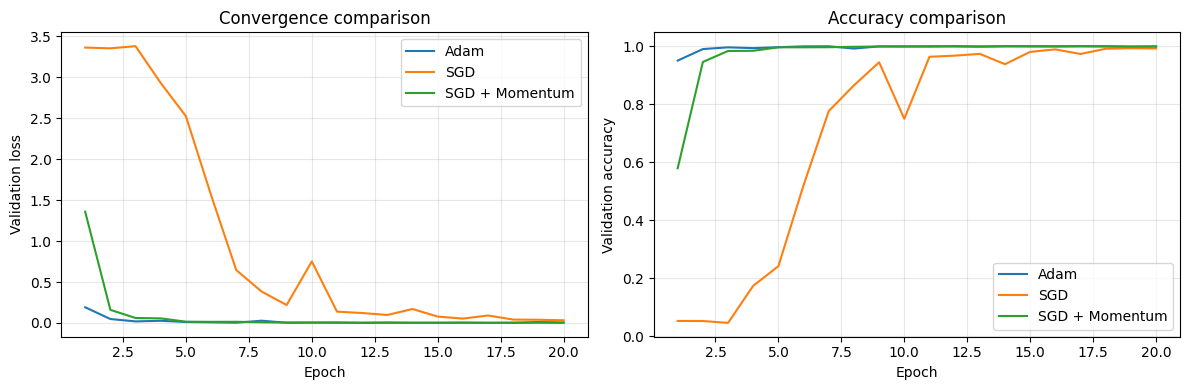

In [ ]:
epochs = range(1, 21)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, history_adam.history["val_loss"], label="Adam")
plt.plot(epochs, history_sgd.history["val_loss"], label="SGD")
plt.plot(epochs, history_momentum.history["val_loss"], label="SGD + Momentum")
plt.xlabel("Epoch")
plt.ylabel("Validation loss")
plt.title("Convergence comparison")
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epochs, history_adam.history["val_accuracy"], label="Adam")
plt.plot(epochs, history_sgd.history["val_accuracy"], label="SGD")
plt.plot(epochs, history_momentum.history["val_accuracy"], label="SGD + Momentum")
plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.title("Accuracy comparison")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

EPOCHS = 20

In [ ]:
tf.keras.utils.set_random_seed(SEED)

model_A_final = tf.keras.models.clone_model(model_A)

model_A_final.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

start = time.perf_counter()

history_A = model_A_final.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    verbose=2
)

time_A = time.perf_counter() - start
print("Average time per epoch:", round(time_A / EPOCHS, 2), "seconds")

Epoch 1/20
1904/1904 - 82s - 43ms/step - accuracy: 0.6338 - loss: 1.1947 - val_accuracy: 0.9471 - val_loss: 0.1859
Epoch 2/20
1904/1904 - 88s - 46ms/step - accuracy: 0.9439 - loss: 0.1752 - val_accuracy: 0.9878 - val_loss: 0.0472
Epoch 3/20
1904/1904 - 73s - 38ms/step - accuracy: 0.9762 - loss: 0.0750 - val_accuracy: 0.9907 - val_loss: 0.0317
Epoch 4/20
1904/1904 - 79s - 41ms/step - accuracy: 0.9846 - loss: 0.0474 - val_accuracy: 0.9976 - val_loss: 0.0092
Epoch 5/20
1904/1904 - 69s - 36ms/step - accuracy: 0.9880 - loss: 0.0373 - val_accuracy: 0.9980 - val_loss: 0.0082
Epoch 6/20
1904/1904 - 82s - 43ms/step - accuracy: 0.9920 - loss: 0.0258 - val_accuracy: 0.9977 - val_loss: 0.0086
Epoch 7/20
1904/1904 - 71s - 37ms/step - accuracy: 0.9929 - loss: 0.0227 - val_accuracy: 0.9985 - val_loss: 0.0058
Epoch 8/20
1904/1904 - 118s - 62ms/step - accuracy: 0.9934 - loss: 0.0214 - val_accuracy: 0.9979 - val_loss: 0.0068
Epoch 9/20
1904/1904 - 70s - 37ms/step - accuracy: 0.9949 - loss: 0.0161 - val_

In [ ]:
tf.keras.utils.set_random_seed(SEED)

model_B_final = tf.keras.models.clone_model(model_B)
assert model_B_final.count_params() <= 100_000

model_B_final.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

start = time.perf_counter()

history_B = model_B_final.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    verbose=2
)

time_B = time.perf_counter() - start
print("Average time per epoch:", round(time_B / EPOCHS, 2), "seconds")

Epoch 1/20
1904/1904 - 96s - 51ms/step - accuracy: 0.2483 - loss: 2.5135 - val_accuracy: 0.6258 - val_loss: 1.2587
Epoch 2/20
1904/1904 - 78s - 41ms/step - accuracy: 0.6832 - loss: 0.9624 - val_accuracy: 0.8292 - val_loss: 0.5164
Epoch 3/20
1904/1904 - 69s - 36ms/step - accuracy: 0.8263 - loss: 0.5081 - val_accuracy: 0.9155 - val_loss: 0.2788
Epoch 4/20
1904/1904 - 78s - 41ms/step - accuracy: 0.8865 - loss: 0.3281 - val_accuracy: 0.9457 - val_loss: 0.1905
Epoch 5/20
1904/1904 - 73s - 38ms/step - accuracy: 0.9172 - loss: 0.2373 - val_accuracy: 0.9697 - val_loss: 0.1097
Epoch 6/20
1904/1904 - 71s - 37ms/step - accuracy: 0.9363 - loss: 0.1851 - val_accuracy: 0.9536 - val_loss: 0.1360
Epoch 7/20
1904/1904 - 81s - 42ms/step - accuracy: 0.9494 - loss: 0.1456 - val_accuracy: 0.9819 - val_loss: 0.0579
Epoch 8/20
1904/1904 - 82s - 43ms/step - accuracy: 0.9567 - loss: 0.1246 - val_accuracy: 0.9854 - val_loss: 0.0489
Epoch 9/20
1904/1904 - 70s - 37ms/step - accuracy: 0.9646 - loss: 0.1027 - val_a

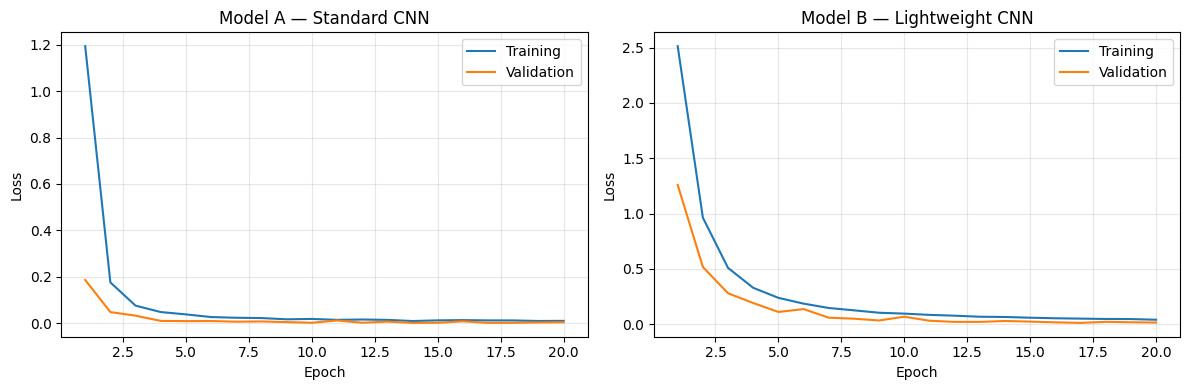

In [ ]:
epochs = range(1, EPOCHS + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, history_A.history["loss"], label="Training")
plt.plot(epochs, history_A.history["val_loss"], label="Validation")
plt.title("Model A — Standard CNN")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epochs, history_B.history["loss"], label="Training")
plt.plot(epochs, history_B.history["val_loss"], label="Validation")
plt.title("Model B — Lightweight CNN")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Model A test accuracy: 0.9989
              precision    recall  f1-score   support

           A     0.9978    1.0000    0.9989       450
           B     1.0000    1.0000    1.0000       450
           C     1.0000    1.0000    1.0000       450
           D     1.0000    1.0000    1.0000       450
           E     0.9956    0.9978    0.9967       450
           F     0.9978    1.0000    0.9989       450
           G     1.0000    1.0000    1.0000       450
           H     1.0000    1.0000    1.0000       450
           I     1.0000    0.9933    0.9967       450
           J     1.0000    1.0000    1.0000       450
           K     1.0000    0.9978    0.9989       450
           L     1.0000    1.0000    1.0000       450
           M     1.0000    1.0000    1.0000       450
           N     1.0000    1.0000    1.0000       450
           O     1.0000    1.0000    1.0000       450
           P     1.0000    1.0000    1.0000       450
           Q     1.0000    1.0000    1.0000       4

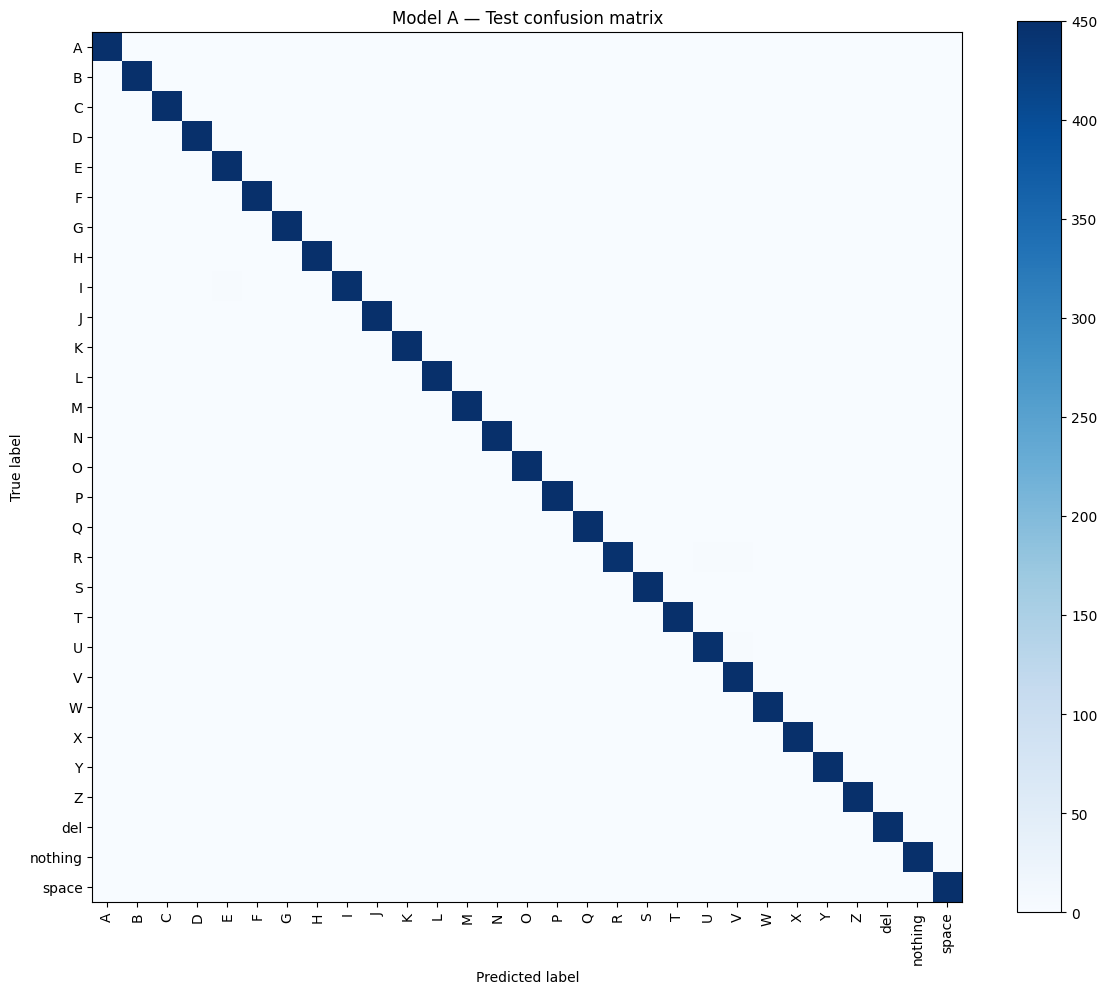

In [ ]:
y_true = test_df["label"].to_numpy()
class_ids = np.arange(NUM_CLASSES)

pred_A = np.argmax(model_A_final.predict(test_ds, verbose=0), axis=1)

accuracy_A = accuracy_score(y_true, pred_A)
precision_A = precision_score(
    y_true, pred_A, labels=class_ids, average="macro", zero_division=0
)
recall_A = recall_score(
    y_true, pred_A, labels=class_ids, average="macro", zero_division=0
)

print("Model A test accuracy:", round(accuracy_A, 4))
print(classification_report(
    y_true, pred_A, labels=class_ids,
    target_names=class_names, digits=4, zero_division=0
))

cm_A = confusion_matrix(y_true, pred_A, labels=class_ids)

fig, ax = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay(cm_A, display_labels=class_names).plot(
    ax=ax, cmap="Blues", xticks_rotation=90, include_values=False
)
plt.title("Model A — Test confusion matrix")
plt.tight_layout()
plt.show()

Model B test accuracy: 0.9967
              precision    recall  f1-score   support

           A     0.9956    1.0000    0.9978       450
           B     1.0000    0.9933    0.9967       450
           C     1.0000    0.9978    0.9989       450
           D     1.0000    1.0000    1.0000       450
           E     0.9956    0.9978    0.9967       450
           F     1.0000    1.0000    1.0000       450
           G     1.0000    0.9956    0.9978       450
           H     0.9956    1.0000    0.9978       450
           I     1.0000    1.0000    1.0000       450
           J     1.0000    1.0000    1.0000       450
           K     0.9978    1.0000    0.9989       450
           L     1.0000    0.9978    0.9989       450
           M     0.9978    0.9978    0.9978       450
           N     0.9978    0.9978    0.9978       450
           O     1.0000    1.0000    1.0000       450
           P     1.0000    1.0000    1.0000       450
           Q     0.9978    1.0000    0.9989       4

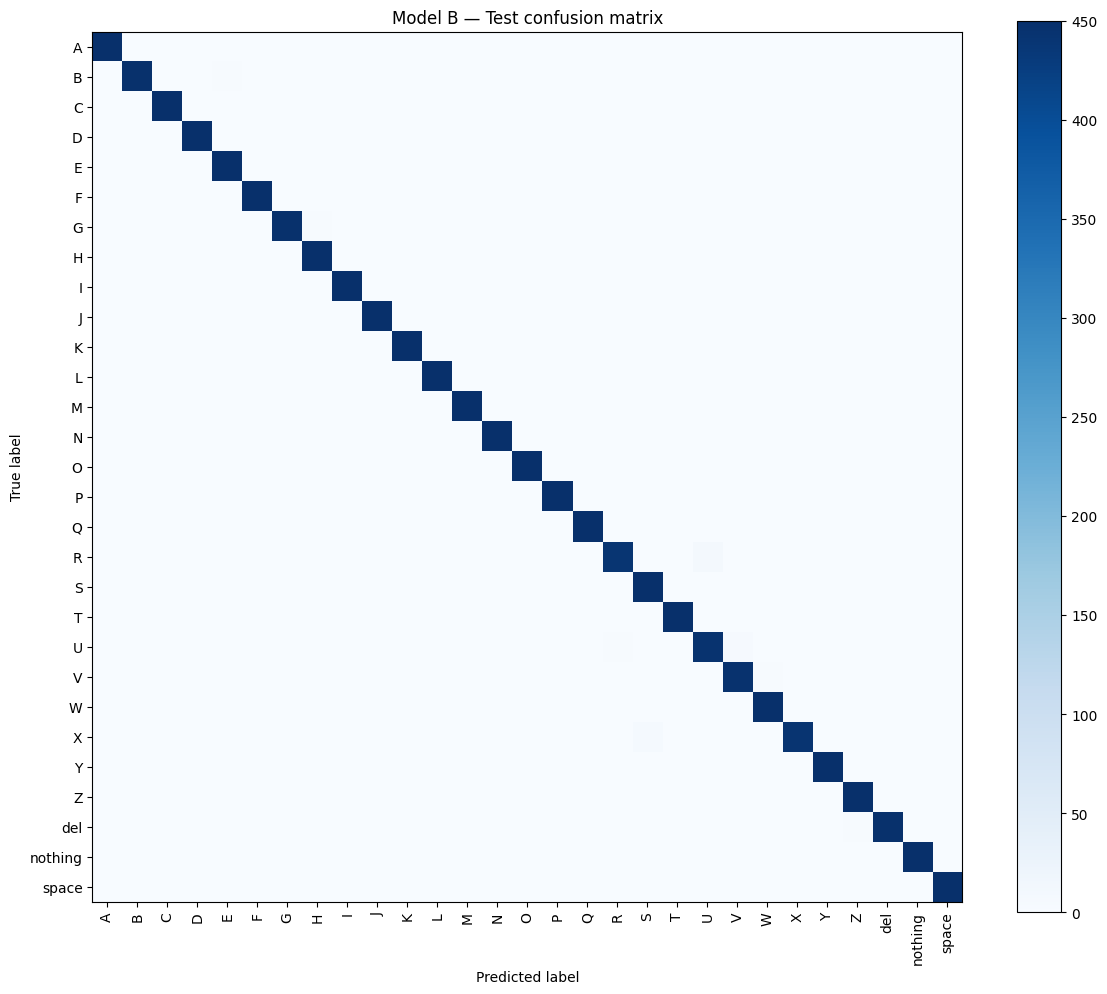

In [ ]:
pred_B = np.argmax(model_B_final.predict(test_ds, verbose=0), axis=1)

accuracy_B = accuracy_score(y_true, pred_B)
precision_B = precision_score(
    y_true, pred_B, labels=class_ids, average="macro", zero_division=0
)
recall_B = recall_score(
    y_true, pred_B, labels=class_ids, average="macro", zero_division=0
)

print("Model B test accuracy:", round(accuracy_B, 4))
print(classification_report(
    y_true, pred_B, labels=class_ids,
    target_names=class_names, digits=4, zero_division=0
))

cm_B = confusion_matrix(y_true, pred_B, labels=class_ids)

fig, ax = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay(cm_B, display_labels=class_names).plot(
    ax=ax, cmap="Blues", xticks_rotation=90, include_values=False
)
plt.title("Model B — Test confusion matrix")
plt.tight_layout()
plt.show()

In [ ]:
params_A = model_A_final.count_params()
params_B = model_B_final.count_params()

comparison = pd.DataFrame({
    "Model": ["A — Standard CNN", "B — Lightweight CNN"],
    "Total parameters": [params_A, params_B],
    "Estimated weight size (KB)": [
        params_A * 4 / 1000,
        params_B * 4 / 1000
    ],
    "Time per epoch (s)": [time_A / EPOCHS, time_B / EPOCHS],
    "Test accuracy (%)": [accuracy_A * 100, accuracy_B * 100],
    "Macro precision": [precision_A, precision_B],
    "Macro recall": [recall_A, recall_B]
})

display(comparison.round(4))

,Model,Total parameters,Estimated weight size (KB),Time per epoch (s),Test accuracy (%),Macro precision,Macro recall
0,A — Standard CNN,244573,978.292,76.7489,99.8851,0.9989,0.9989
1,B — Lightweight CNN,32856,131.424,76.0754,99.6705,0.9967,0.9967


In [ ]:
Path("results").mkdir(exist_ok=True)

model_A_final.save("results/model_A.keras")
model_B_final.save("results/model_B.keras")

pd.DataFrame(history_A.history).to_csv("results/history_A.csv", index=False)
pd.DataFrame(history_B.history).to_csv("results/history_B.csv", index=False)
comparison.to_csv("results/custom_model_comparison.csv", index=False)

In [ ]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from tensorflow.keras import layers
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

In [ ]:
tf.keras.utils.set_random_seed(SEED)

mobile_base = tf.keras.applications.MobileNetV2(
    input_shape=(64, 64, 3),
    include_top=False,
    weights="imagenet"
)
mobile_base.trainable = False

inputs = layers.Input(shape=(64, 64, 3))
x = layers.Rescaling(1 / 127.5, offset=-1)(inputs)
x = mobile_base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

model_mobile = tf.keras.Model(inputs, outputs)

model_mobile.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_mobile_head = model_mobile.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    verbose=2
)

/tmp/ipykernel_1977/3027410001.py:3: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  mobile_base = tf.keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
1904/1904 - 97s - 51ms/step - accuracy: 0.7927 - loss: 0.7605 - val_accuracy: 0.9252 - val_loss: 0.3120
Epoch 2/5
1904/1904 - 68s - 36ms/step - accuracy: 0.9098 - loss: 0.3179 - val_accuracy: 0.9523 - val_loss: 0.1996
Epoch 3/5
1904/1904 - 82s - 43ms/step - accuracy: 0.9281 - loss: 0.2423 - val_accuracy: 0.9611 - val_loss: 0.1588
Epoch 4/5
1904/1904 - 67s - 35ms/step - accuracy: 0.9379 - loss: 0.2057 - val_accuracy: 0.9643 - val_loss: 0.1364
Epoch 5/5
1904/1904 - 75s - 39ms/step - accuracy: 0.9446 - loss: 0.1823 - val_accuracy: 0.9682 - val_loss: 0.1168


In [ ]:
mobile_base.trainable = True

model_mobile.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_mobile_fine = model_mobile.fit(
    train_ds,
    validation_data=val_ds,
    initial_epoch=5,
    epochs=20,
    verbose=2
)

Epoch 6/20
1904/1904 - 159s - 84ms/step - accuracy: 0.3425 - loss: 4.7346 - val_accuracy: 0.5855 - val_loss: 1.6344
Epoch 7/20
1904/1904 - 75s - 40ms/step - accuracy: 0.5671 - loss: 1.6620 - val_accuracy: 0.7758 - val_loss: 0.7286
Epoch 8/20
1904/1904 - 82s - 43ms/step - accuracy: 0.7120 - loss: 0.9807 - val_accuracy: 0.8743 - val_loss: 0.3979
Epoch 9/20
1904/1904 - 86s - 45ms/step - accuracy: 0.8128 - loss: 0.6029 - val_accuracy: 0.9339 - val_loss: 0.2065
Epoch 10/20
1904/1904 - 75s - 40ms/step - accuracy: 0.8750 - loss: 0.3908 - val_accuracy: 0.9631 - val_loss: 0.1069
Epoch 11/20
1904/1904 - 84s - 44ms/step - accuracy: 0.9151 - loss: 0.2625 - val_accuracy: 0.9790 - val_loss: 0.0638
Epoch 12/20
1904/1904 - 75s - 40ms/step - accuracy: 0.9415 - loss: 0.1773 - val_accuracy: 0.9896 - val_loss: 0.0357
Epoch 13/20
1904/1904 - 74s - 39ms/step - accuracy: 0.9576 - loss: 0.1287 - val_accuracy: 0.9931 - val_loss: 0.0225
Epoch 14/20
1904/1904 - 84s - 44ms/step - accuracy: 0.9691 - loss: 0.0944 -

In [ ]:
tf.keras.utils.set_random_seed(SEED)

efficient_base = tf.keras.applications.EfficientNetB0(
    input_shape=(64, 64, 3),
    include_top=False,
    weights="imagenet"
)
efficient_base.trainable = False

inputs = layers.Input(shape=(64, 64, 3))
x = efficient_base(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

model_efficient = tf.keras.Model(inputs, outputs)

model_efficient.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_efficient_head = model_efficient.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    verbose=2
)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
1904/1904 - 138s - 73ms/step - accuracy: 0.7732 - loss: 0.9045 - val_accuracy: 0.9191 - val_loss: 0.3596
Epoch 2/5
1904/1904 - 85s - 45ms/step - accuracy: 0.8884 - loss: 0.4140 - val_accuracy: 0.9536 - val_loss: 0.2222
Epoch 3/5
1904/1904 - 74s - 39ms/step - accuracy: 0.9060 - loss: 0.3248 - val_accuracy: 0.9628 - val_loss: 0.1704
Epoch 4/5
1904/1904 - 80s - 42ms/step - accuracy: 0.9183 - loss: 0.2805 - val_accuracy: 0.9689 - val_loss: 0.1390
Epoch 5/5
1904/1904 - 79s - 42ms/step - accuracy: 0.9223 - loss: 0.2559 - val_accuracy: 0.9723 - val_loss: 0.1217


In [ ]:
efficient_base.trainable = True

model_efficient.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_efficient_fine = model_efficient.fit(
    train_ds,
    validation_data=val_ds,
    initial_epoch=5,
    epochs=20,
    verbose=2
)

Epoch 6/20
1904/1904 - 219s - 115ms/step - accuracy: 0.4988 - loss: 2.6417 - val_accuracy: 0.7964 - val_loss: 0.7187
Epoch 7/20
1904/1904 - 107s - 56ms/step - accuracy: 0.7559 - loss: 0.9310 - val_accuracy: 0.9215 - val_loss: 0.2349
Epoch 8/20
1904/1904 - 83s - 44ms/step - accuracy: 0.8593 - loss: 0.4872 - val_accuracy: 0.9679 - val_loss: 0.0927
Epoch 9/20
1904/1904 - 85s - 45ms/step - accuracy: 0.9114 - loss: 0.2886 - val_accuracy: 0.9865 - val_loss: 0.0426
Epoch 10/20
1904/1904 - 142s - 74ms/step - accuracy: 0.9392 - loss: 0.1887 - val_accuracy: 0.9923 - val_loss: 0.0232
Epoch 11/20
1904/1904 - 87s - 46ms/step - accuracy: 0.9587 - loss: 0.1249 - val_accuracy: 0.9956 - val_loss: 0.0126
Epoch 12/20
1904/1904 - 139s - 73ms/step - accuracy: 0.9710 - loss: 0.0896 - val_accuracy: 0.9975 - val_loss: 0.0082
Epoch 13/20
1904/1904 - 143s - 75ms/step - accuracy: 0.9772 - loss: 0.0690 - val_accuracy: 0.9986 - val_loss: 0.0045
Epoch 14/20
1904/1904 - 94s - 49ms/step - accuracy: 0.9817 - loss: 0.0

In [ ]:
y_true = test_df["label"].to_numpy()
class_ids = np.arange(NUM_CLASSES)

pred_mobile = np.argmax(
    model_mobile.predict(test_ds, verbose=0), axis=1
)

report_mobile = classification_report(
    y_true,
    pred_mobile,
    labels=class_ids,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

display(pd.DataFrame(report_mobile).T.round(4))

,precision,recall,f1-score,support
A,1.0000,1.0000,1.0000,450.0000
B,1.0000,1.0000,1.0000,450.0000
C,1.0000,1.0000,1.0000,450.0000
D,1.0000,1.0000,1.0000,450.0000
E,1.0000,1.0000,1.0000,450.0000
F,1.0000,1.0000,1.0000,450.0000
G,1.0000,1.0000,1.0000,450.0000
H,1.0000,1.0000,1.0000,450.0000
I,1.0000,1.0000,1.0000,450.0000
J,1.0000,1.0000,1.0000,450.0000


In [ ]:
pred_efficient = np.argmax(
    model_efficient.predict(test_ds, verbose=0), axis=1
)

report_efficient = classification_report(
    y_true,
    pred_efficient,
    labels=class_ids,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

display(pd.DataFrame(report_efficient).T.round(4))

,precision,recall,f1-score,support
A,1.0000,1.0000,1.0000,450.0000
B,1.0000,1.0000,1.0000,450.0000
C,1.0000,1.0000,1.0000,450.0000
D,1.0000,1.0000,1.0000,450.0000
E,1.0000,1.0000,1.0000,450.0000
F,1.0000,1.0000,1.0000,450.0000
G,1.0000,1.0000,1.0000,450.0000
H,1.0000,1.0000,1.0000,450.0000
I,1.0000,1.0000,1.0000,450.0000
J,1.0000,1.0000,1.0000,450.0000


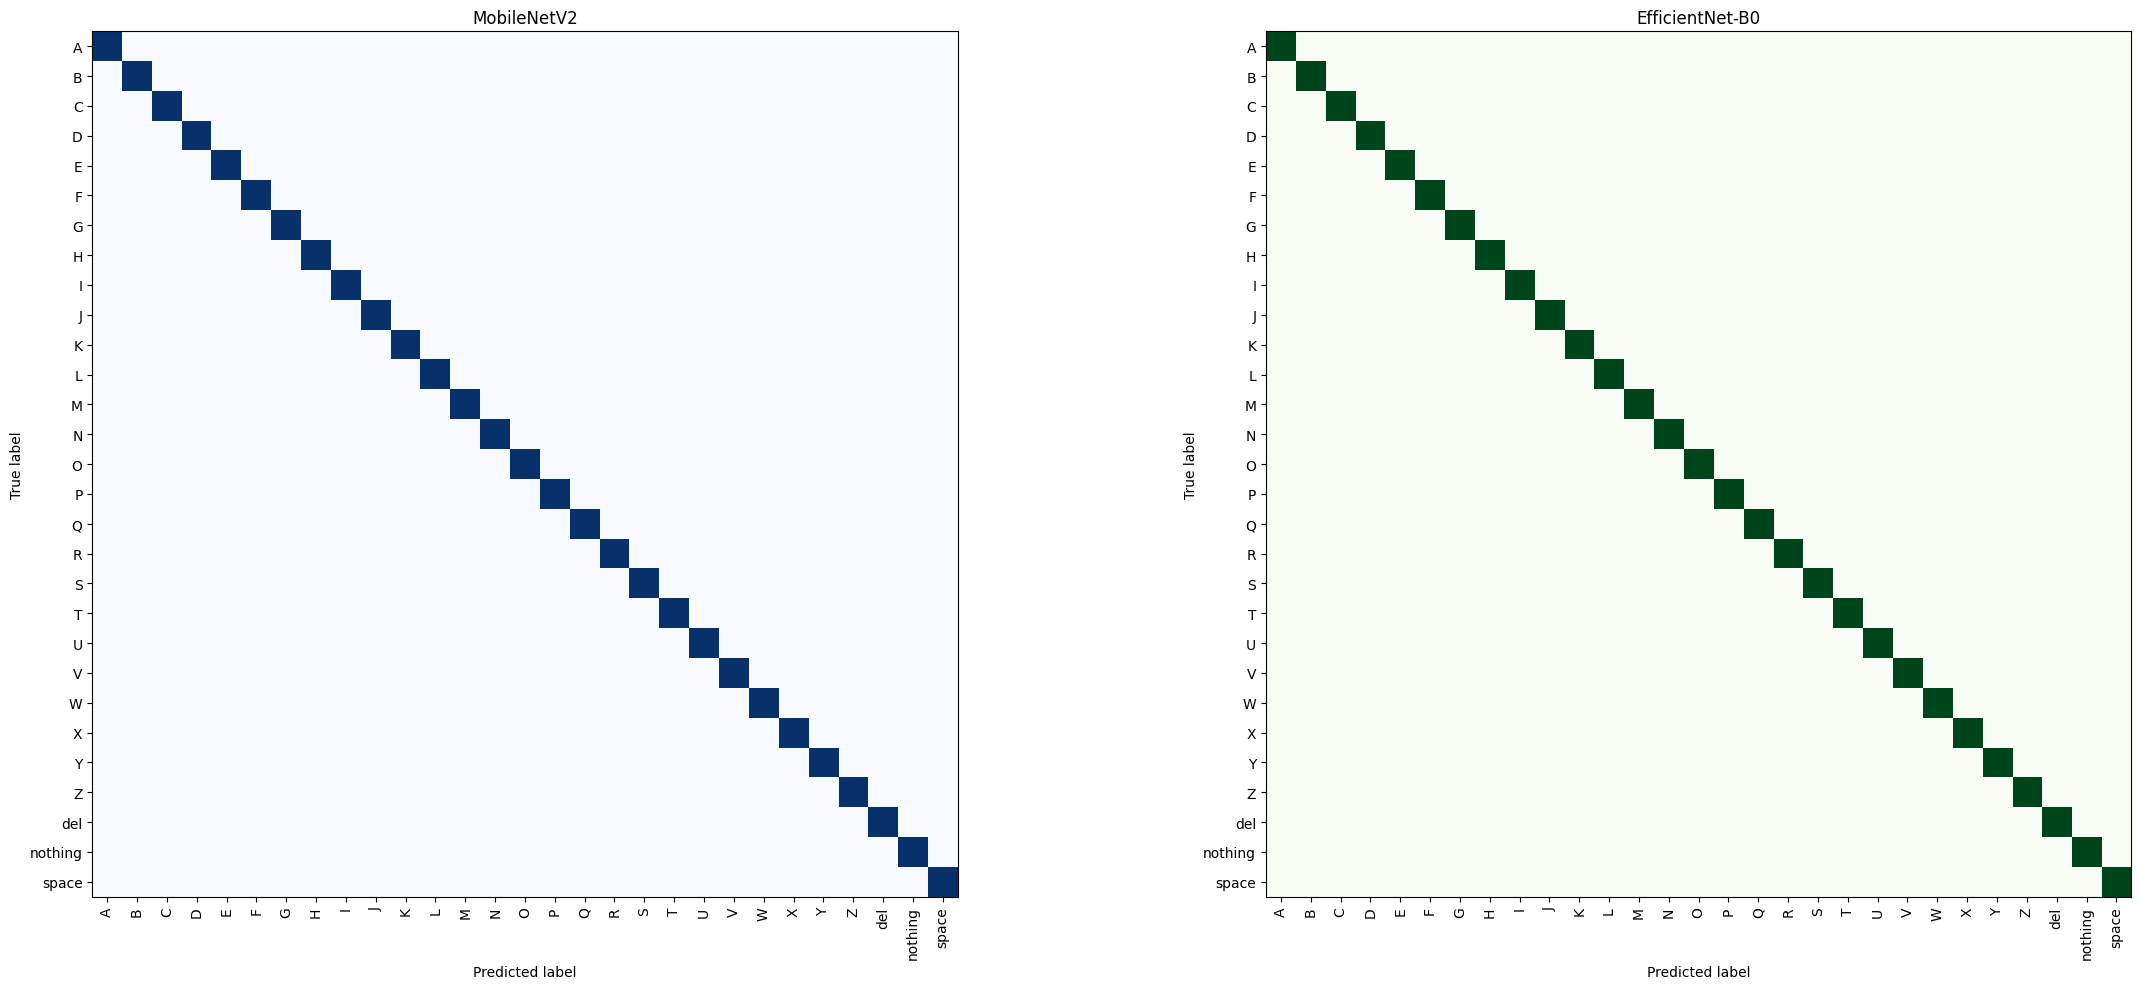

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(24, 10))

ConfusionMatrixDisplay.from_predictions(
    y_true, pred_mobile,
    labels=class_ids,
    display_labels=class_names,
    ax=axes[0],
    cmap="Blues",
    xticks_rotation=90,
    include_values=False,
    colorbar=False
)
axes[0].set_title("MobileNetV2")

ConfusionMatrixDisplay.from_predictions(
    y_true, pred_efficient,
    labels=class_ids,
    display_labels=class_names,
    ax=axes[1],
    cmap="Greens",
    xticks_rotation=90,
    include_values=False,
    colorbar=False
)
axes[1].set_title("EfficientNet-B0")

plt.tight_layout()
plt.show()

In [ ]:
Path("results").mkdir(exist_ok=True)

mobile_export = tf.keras.Model(
    model_mobile.inputs, model_mobile.outputs
)
efficient_export = tf.keras.Model(
    model_efficient.inputs, model_efficient.outputs
)

mobile_export.save("results/mobilenet_v2.keras")
efficient_export.save("results/efficientnet_b0.keras")

mobile_size = Path("results/mobilenet_v2.keras").stat().st_size / 1_000_000
efficient_size = Path("results/efficientnet_b0.keras").stat().st_size / 1_000_000

In [ ]:
sota_comparison = pd.DataFrame({
    "Model": ["MobileNetV2", "EfficientNet-B0"],

    "Total parameters": [
        model_mobile.count_params(),
        model_efficient.count_params()
    ],

    "Saved model size (MB)": [
        mobile_size,
        efficient_size
    ],

    "Estimated FP32 weights (MB)": [
        model_mobile.count_params() * 4 / 1_000_000,
        model_efficient.count_params() * 4 / 1_000_000
    ],

    "Test accuracy (%)": [
        report_mobile["accuracy"] * 100,
        report_efficient["accuracy"] * 100
    ],

    "Macro precision": [
        report_mobile["macro avg"]["precision"],
        report_efficient["macro avg"]["precision"]
    ],

    "Macro recall": [
        report_mobile["macro avg"]["recall"],
        report_efficient["macro avg"]["recall"]
    ],

    "Macro F1": [
        report_mobile["macro avg"]["f1-score"],
        report_efficient["macro avg"]["f1-score"]
    ]
})

display(sota_comparison.round(4))
sota_comparison.to_csv("results/sota_comparison.csv", index=False)

,Model,Total parameters,Saved model size (MB),Estimated FP32 weights (MB),Test accuracy (%),Macro precision,Macro recall,Macro F1
0,MobileNetV2,2295133,9.7667,9.1805,99.9464,0.9995,0.9995,0.9995
1,EfficientNet-B0,4086720,17.1880,16.3469,99.9923,0.9999,0.9999,0.9999
